# Data Graph and exploration

In [4]:
# Read Data from challenge folder 
import pandas as pd
import json

# Read the JSON file
with open('challenge/dataset.json', 'r') as f:
    data_json = json.load(f)

# Display basic info about the JSON data
print("JSON data type:", type(data_json))
print("JSON keys:" if isinstance(data_json, dict) else "JSON length:", 
      list(data_json.keys()) if isinstance(data_json, dict) else len(data_json))
print(data_json)

# Read the Excel file
df_cooccurrence = pd.read_excel('/Users/enlt-dlopes/Documents/Dev_Notebooks/Nadara/challenge/Nintendo_Cooccurrence_Matrix.xlsx')
# Col Unamed Unnamed: 0 now called Product
df_cooccurrence.rename(columns={'Unnamed: 0': 'Product'}, inplace=True)
# Display basic info about the Excel data
print("\nCooccurrence Matrix shape:", df_cooccurrence.shape)
df_cooccurrence

JSON data type: <class 'dict'>
JSON keys: ['Console', 'Games', 'Accessories']
{'Console': [{'name': 'Nintendo Switch', 'Store A': 200000, 'Store B': 150000, 'Store C': 150000, 'category': 'Console', 'times_sold': 500000}], 'Games': [{'name': 'Zelda: Breath of the Wild', 'release_date': '2017-03-03', 'times_sold': 250000, 'Store A': 120000, 'Store B': 80000, 'Store C': 50000, 'type': 'Adventure', 'category': 'Game', 'franchise': 'The Legend of Zelda', 'min_age': 12}, {'name': 'Zelda: Tears of the Kingdom', 'release_date': '2023-05-12', 'times_sold': 350000, 'Store A': 200000, 'Store B': 100000, 'Store C': 50000, 'type': 'Adventure', 'category': 'Game', 'franchise': 'The Legend of Zelda', 'min_age': 12}, {'name': 'Super Mario Odyssey', 'release_date': '2017-10-27', 'times_sold': 400000, 'Store A': 150000, 'Store B': 100000, 'Store C': 150000, 'type': 'Platformer', 'category': 'Game', 'franchise': 'Super Mario', 'min_age': 7}, {'name': 'Mario Kart 8 Deluxe', 'release_date': '2017-04-28', 

,Product,Nintendo Switch,Zelda: Breath of the Wild,Zelda: Tears of the Kingdom,Super Mario Odyssey,Mario Kart 8 Deluxe,Mario Party Superstars,Sonic Generations,Sonic Mania,Animal Crossing: New Horizons,Splatoon 3,Pikmin 4,Nintendo Switch Pro Controller,Joy-Con Controllers (Pair),Nintendo Switch Dock Set,Nintendo Switch Carrying Case,Nintendo Switch Screen Protector
0,Nintendo Switch,50000,30000,50000,60000,40000,20000,10000,10000,100000,30000,5000,50000,20000,10000,10000,5000
1,Zelda: Breath of the Wild,30000,100000,20000,15000,10000,5000,2000,3000,30000,20000,2000,5000,3000,2000,2000,1000
2,Zelda: Tears of the Kingdom,50000,20000,150000,25000,15000,10000,5000,5000,30000,20000,2000,10000,3000,2000,2000,1000
3,Super Mario Odyssey,60000,15000,25000,200000,30000,20000,5000,5000,25000,10000,2000,2000,1000,0,0,0
4,Mario Kart 8 Deluxe,40000,10000,15000,30000,150000,10000,2000,3000,13000,15000,1000,5000,3000,2000,1000,0
5,Mario Party Superstars,20000,5000,10000,20000,10000,100000,2000,3000,15000,10000,1000,5000,2000,1000,1000,0
6,Sonic Generations,10000,2000,5000,5000,2000,2000,90000,10000,10000,10000,1000,3000,2000,1000,1000,1000
7,Sonic Mania,10000,3000,5000,5000,3000,3000,10000,125000,20000,15000,1000,3000,2000,1000,1000,1000
8,Animal Crossing: New Horizons,100000,30000,30000,25000,13000,15000,10000,20000,400000,50000,10000,100000,50000,10000,10000,10000
9,Splatoon 3,30000,20000,20000,10000,15000,10000,10000,15000,50000,250000,10000,50000,30000,10000,5000,5000


/var/folders/2_/w4w00tzx0r975_q9mkp6skxr0000gp/T/ipykernel_34019/1927915089.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sales_per_product.index, y=sales_per_product.values, palette="viridis")


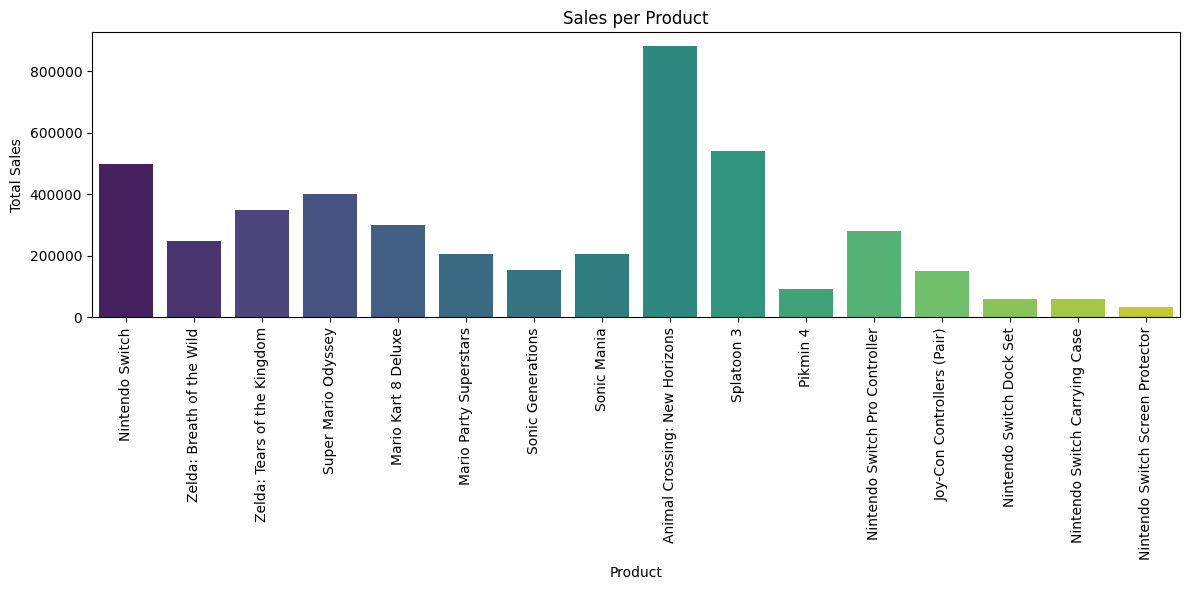

In [14]:
# PLOT GRAPHS occurence of sales per product 
import matplotlib.pyplot as plt
import seaborn as sns
# Sum the sales for each product
sales_per_product = df_cooccurrence.set_index('Product').sum(axis=1)
# Plot the sales per product
plt.figure(figsize=(12, 6))
sns.barplot(x=sales_per_product.index, y=sales_per_product.values, palette="viridis")
plt.xticks(rotation=90)
plt.title('Sales per Product')
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

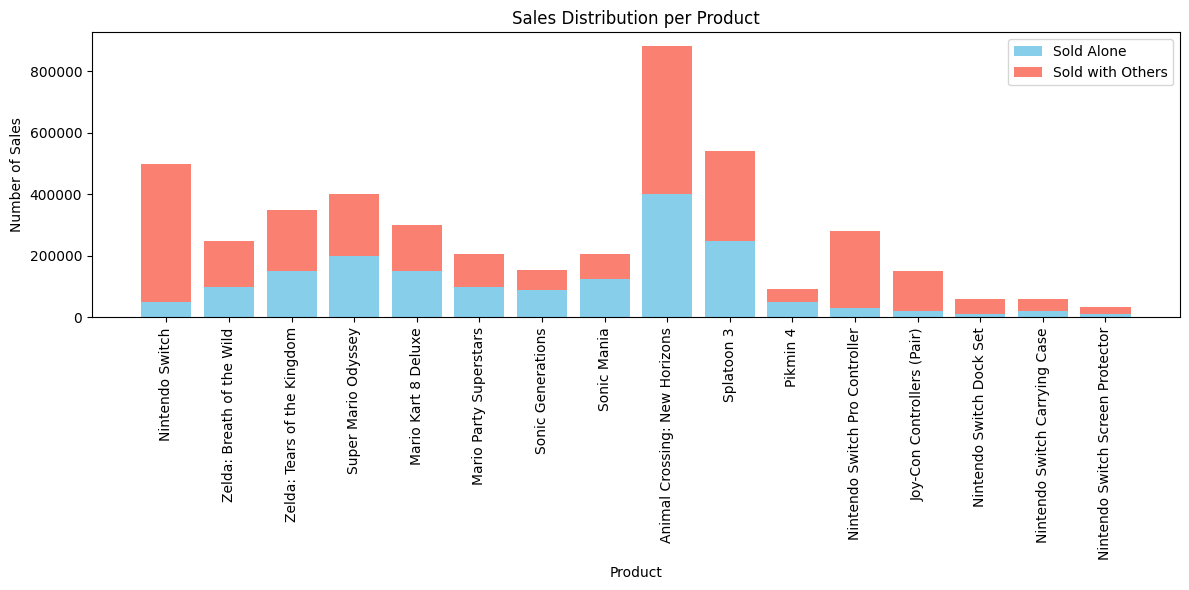

In [17]:
## PPlot number of times product sold alone (diagonal) and when sold with other product (non-diagonal)
import numpy as np
import matplotlib.pyplot as plt
# Calculate diagonal and non-diagonal sales
diagonal_sales = df_cooccurrence.set_index('Product').values.diagonal()
non_diagonal_sales = sales_per_product.values - diagonal_sales
labels = df_cooccurrence['Product']
x = range(len(labels))
plt.figure(figsize=(12, 6))
plt.bar(x, diagonal_sales, label='Sold Alone', color='skyblue')
plt.bar(x, non_diagonal_sales, bottom=diagonal_sales, label='Sold with Others', color='salmon')
plt.xticks(x, labels, rotation=90)
plt.title('Sales Distribution per Product')
plt.xlabel('Product')
plt.ylabel('Number of Sales')
plt.legend()
plt.tight_layout()
plt.show()

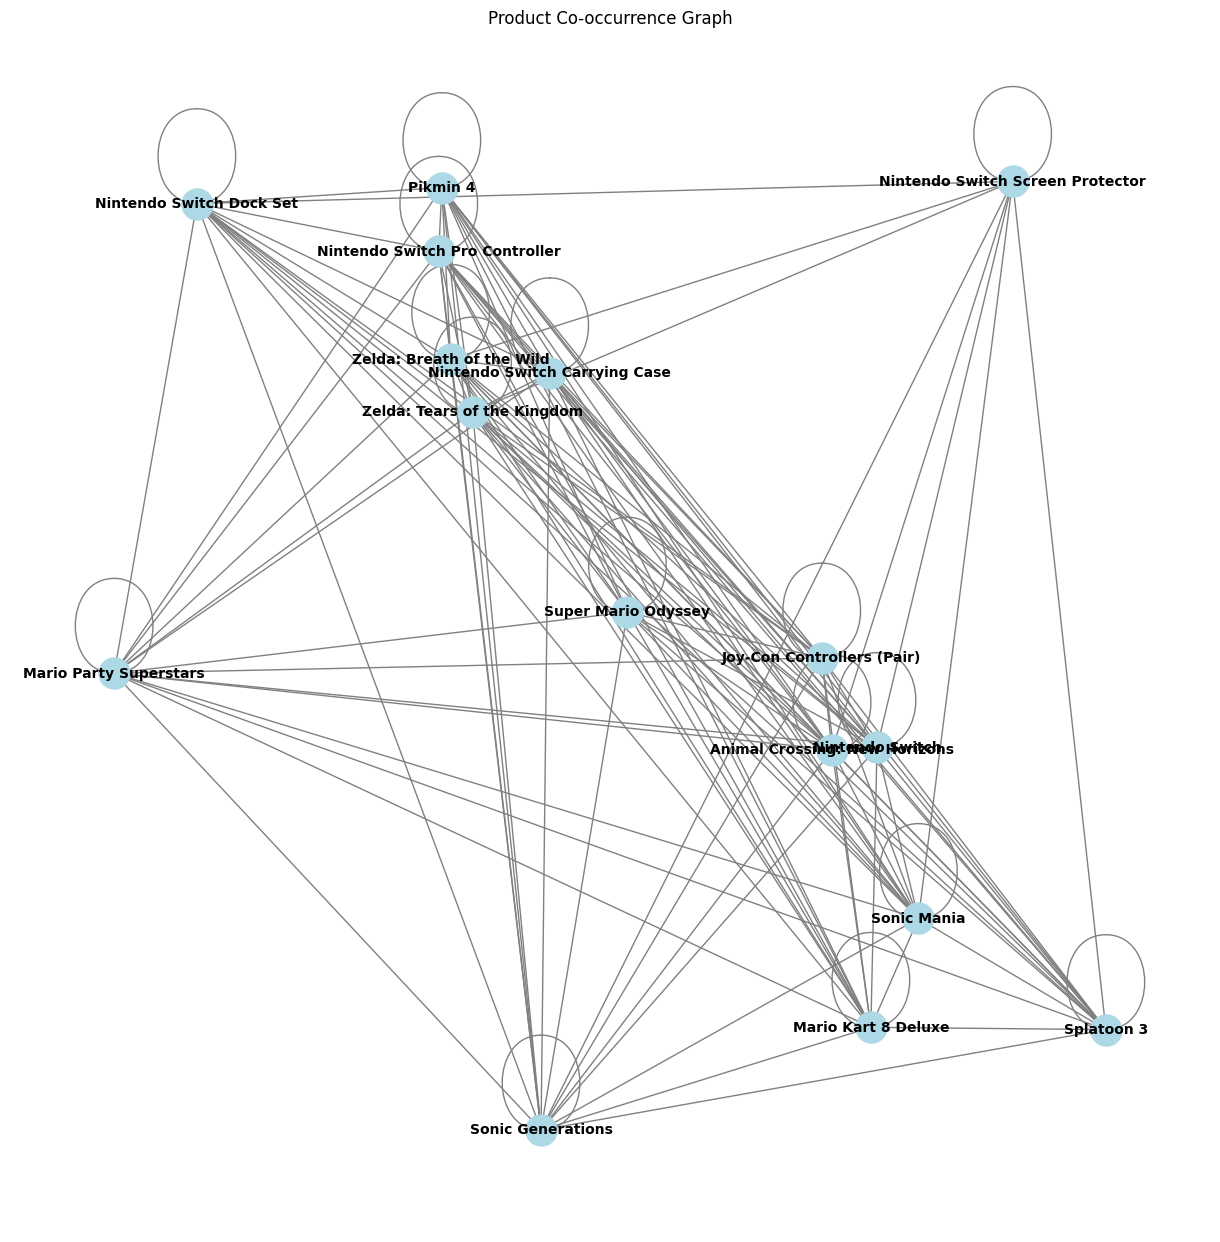

In [9]:
# Graphic analysis about co-occurence between products
import networkx as nx
# Create a graph from the co-occurrence matrix
G = nx.from_pandas_adjacency(df_cooccurrence.set_index('Product'))
# Draw the graph    
plt.figure(figsize=(12, 12))
pos = nx.spring_layout(G, k=0.15, iterations=20)
nx.draw(G, pos, with_labels=True, node_size=500, node_color='lightblue', font_size=10, font_weight='bold', edge_color='gray')
plt.title('Product Co-occurrence Graph')
plt.show()  

In [10]:
# Create a conditional_prob matrix based on co-occurence matrix
cooccurrence_matrix = df_cooccurrence.set_index('Product').values
# Calculate the sum of each row
row_sums = cooccurrence_matrix.sum(axis=1, keepdims=True)
# Avoid division by zero
row_sums[row_sums == 0] = 1
# Calculate the conditional probability matrix
conditional_prob_matrix = cooccurrence_matrix / row_sums
# Convert back to DataFrame for easier handling
conditional_prob_df = pd.DataFrame(conditional_prob_matrix, index=df_cooccurrence['Product'], columns=df_cooccurrence['Product'])
conditional_prob_df

Product,Nintendo Switch,Zelda: Breath of the Wild,Zelda: Tears of the Kingdom,Super Mario Odyssey,Mario Kart 8 Deluxe,Mario Party Superstars,Sonic Generations,Sonic Mania,Animal Crossing: New Horizons,Splatoon 3,Pikmin 4,Nintendo Switch Pro Controller,Joy-Con Controllers (Pair),Nintendo Switch Dock Set,Nintendo Switch Carrying Case,Nintendo Switch Screen Protector
Product,,,,,,,,,,,,,,,,
Nintendo Switch,0.100000,0.060000,0.100000,0.120000,0.080000,0.040000,0.020000,0.020000,0.200000,0.060000,0.010000,0.100000,0.040000,0.020000,0.020000,0.010000
Zelda: Breath of the Wild,0.120000,0.400000,0.080000,0.060000,0.040000,0.020000,0.008000,0.012000,0.120000,0.080000,0.008000,0.020000,0.012000,0.008000,0.008000,0.004000
Zelda: Tears of the Kingdom,0.142857,0.057143,0.428571,0.071429,0.042857,0.028571,0.014286,0.014286,0.085714,0.057143,0.005714,0.028571,0.008571,0.005714,0.005714,0.002857
Super Mario Odyssey,0.150000,0.037500,0.062500,0.500000,0.075000,0.050000,0.012500,0.012500,0.062500,0.025000,0.005000,0.005000,0.002500,0.000000,0.000000,0.000000
Mario Kart 8 Deluxe,0.133333,0.033333,0.050000,0.100000,0.500000,0.033333,0.006667,0.010000,0.043333,0.050000,0.003333,0.016667,0.010000,0.006667,0.003333,0.000000
Mario Party Superstars,0.097561,0.024390,0.048780,0.097561,0.048780,0.487805,0.009756,0.014634,0.073171,0.048780,0.004878,0.024390,0.009756,0.004878,0.004878,0.000000
Sonic Generations,0.064516,0.012903,0.032258,0.032258,0.012903,0.012903,0.580645,0.064516,0.064516,0.064516,0.006452,0.019355,0.012903,0.006452,0.006452,0.006452
Sonic Mania,0.048077,0.014423,0.024038,0.024038,0.014423,0.014423,0.048077,0.600962,0.096154,0.072115,0.004808,0.014423,0.009615,0.004808,0.004808,0.004808
Animal Crossing: New Horizons,0.113250,0.033975,0.033975,0.028313,0.014723,0.016988,0.011325,0.022650,0.453001,0.056625,0.011325,0.113250,0.056625,0.011325,0.011325,0.011325


/var/folders/2_/w4w00tzx0r975_q9mkp6skxr0000gp/T/ipykernel_34019/554601135.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=conditional_prob_df.columns, y=conditional_prob_df.loc[product_name], palette="magma")


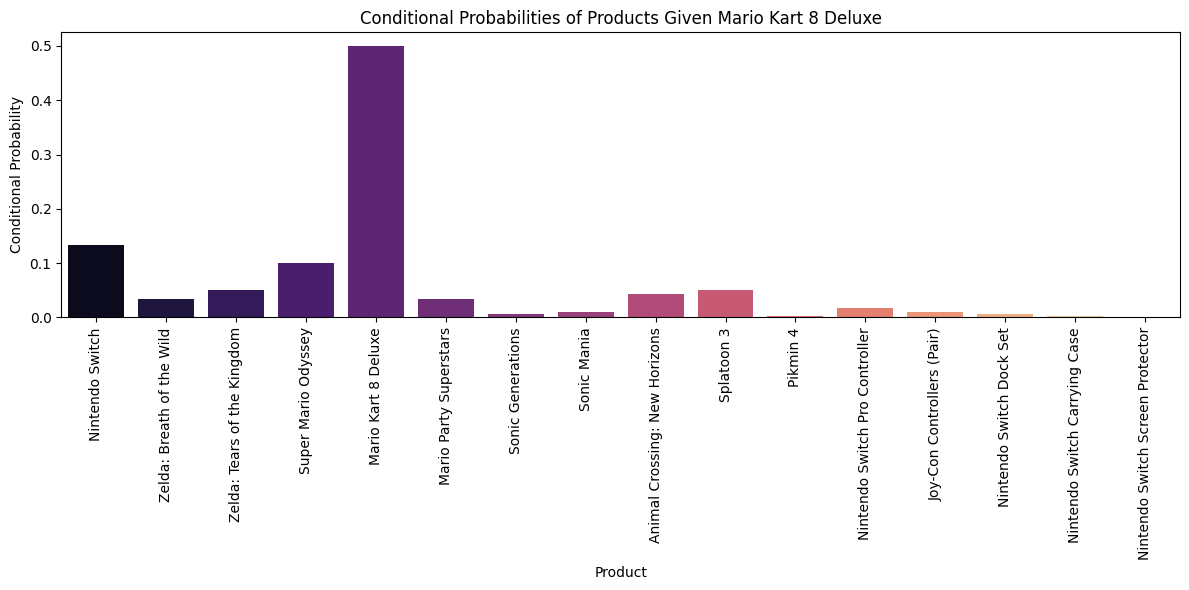

In [11]:
# Bar plot of conditional probabilities for a specific product
product_name = 'Mario Kart 8 Deluxe'
if product_name in conditional_prob_df.index:
    plt.figure(figsize=(12, 6))
    sns.barplot(x=conditional_prob_df.columns, y=conditional_prob_df.loc[product_name], palette="magma")
    plt.xticks(rotation=90)
    plt.title(f'Conditional Probabilities of Products Given {product_name}')
    plt.xlabel('Product')
    plt.ylabel('Conditional Probability')
    plt.tight_layout()
    plt.show()
else:
    print(f"Product '{product_name}' not found in the conditional probability matrix.")

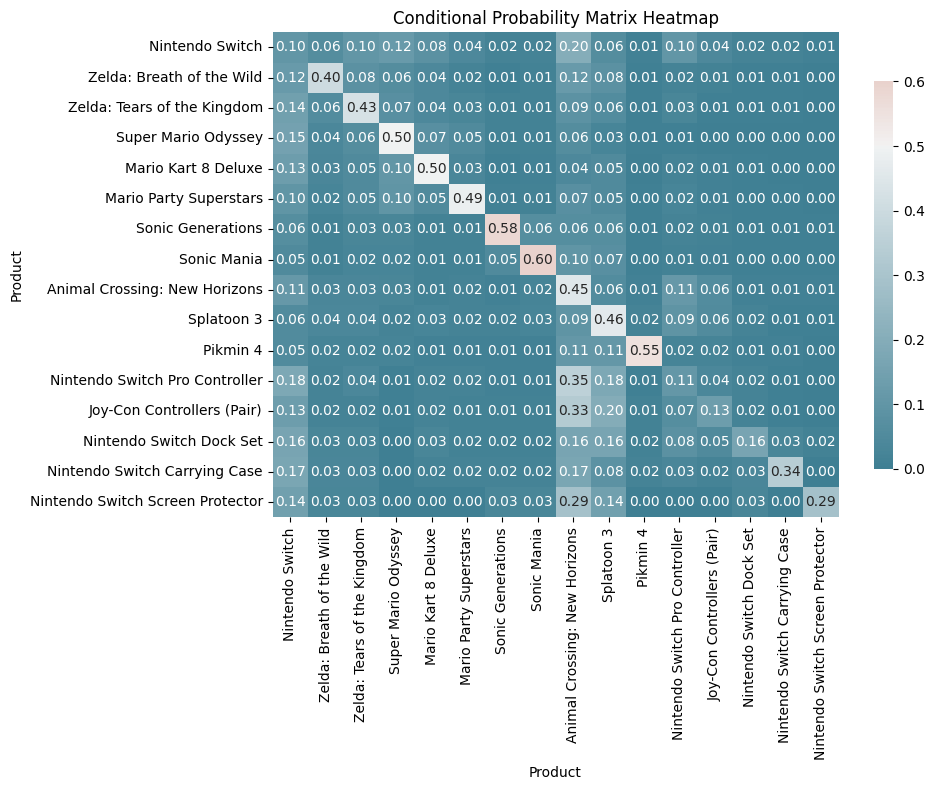

In [12]:
# Color code conditional_prob_df to understand higher and lower correlations between products 
import numpy as np
# Create a color-coded matrix
plt.figure(figsize=(10, 8))
cmap = sns.diverging_palette(220, 20, as_cmap=True)
sns.heatmap(conditional_prob_df, cmap=cmap, center=0.5, annot=True, fmt=".2f", cbar_kws={"shrink": .8})
plt.title('Conditional Probability Matrix Heatmap')
plt.tight_layout()
plt.show()